# 06 – Convolutional network (CNN) + distillation (pion)

## 1. Introduction

Instead of formulas, here a **convolutional neural network** learns the shape, without a predefined functional form.
For every momentum, the network outputs a full probability map on the $(z', r)$ grid. It is trained with the same detector convolution and
likelihood as the GFlash formula (01) and the MLP (05), so they are directly comparable.

**How does the CNN (convolutional decoder) work?** From the momentum, the network builds a small $8 \times 2$ "sketch" image, then in four steps
upsamples it by a factor of two and refines it with convolutional filters after each step, until it reaches the $128 \times 32$ grid.
The momentum enters every step as a modulation (FiLM). It is like a **painter starting from a rough sketch** and adding, step by step,
ever finer details. The convolution also naturally handles smoothness between neighbouring cells.

**How large should the network be?** For the MLP (05) the architecture was chosen by a validation search. Training the CNN is about 4 times more expensive, so
here we **do not search**: the architecture is **derived** from the task and the data (section 3), then **verified with a single training run**
to have sufficient capacity (4b): the validation NLL must not be detectably worse than that of the validated-sufficient MLP.

**Distillation (symbolic regression):** the trained network is "translated" into an analytic formula, just as for the MLP.

**Unified comparison (section 7):** the CNN and CNN-formula $r_{95}$ are added to the previous shapes (GFlash, envelope, drop, MLP, MLP-formula).

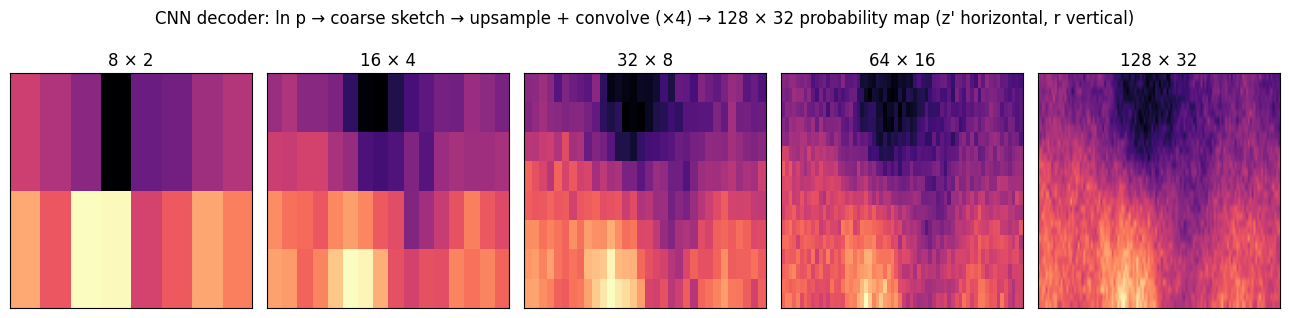

In [1]:
import matplotlib.pyplot as plt, torch, torch.nn.functional as F
torch.manual_seed(3)
img = torch.randn(1, 1, 8, 2) + torch.tensor([[[[2.0, 0.5]] * 3 + [[1.0, 0.2]] * 5]]).reshape(1, 1, 8, 2)
stages = [img]
for _ in range(4):
    stages.append(F.interpolate(stages[-1], scale_factor=2, mode="bilinear") + 0.15 * torch.randn(1, 1, *[2 * s for s in stages[-1].shape[2:]]))
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2))
for ax, s in zip(axes, stages):
    ax.imshow(s[0, 0].T.numpy(), origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"{s.shape[2]} × {s.shape[3]}"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("CNN decoder: ln p → coarse sketch → upsample + convolve (×4) → 128 × 32 probability map (z' horizontal, r vertical)")
plt.tight_layout(); plt.show()

## 2. Loading the data

In [2]:
PARTICLES = ['pion']
DATA_DIR = "../../data/simulations/regression-pion/"          # a CSV-k helye
OUT_DIR = "results"        # models and exports are stored here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-pion/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

pion: 99689 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69783, val 14950, test 14956

===== pion =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49110973 entries, 0 to 49110972
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                floa

,count,mean,std,min,25%,50%,75%,max
event_number,49110973.0,1.050066e+05,6.065561e+04,0.000000e+00,5.237000e+04,1.050170e+05,1.575570e+05,2.099970e+05
cellID,49110973.0,2.090493e+09,1.473656e+09,4.212000e+03,7.221679e+08,1.753932e+09,3.309956e+09,5.063386e+09
x,49110973.0,3.218513e+00,1.306847e+03,-2.596035e+03,-1.036428e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,49110973.0,-2.283059e+00,1.307162e+03,-2.599800e+03,-1.036200e+03,2.620000e+01,1.036200e+03,2.599800e+03
z,49110973.0,4.091779e+03,2.837958e+02,3.662400e+03,3.867400e+03,4.051900e+03,4.277400e+03,4.871900e+03
x_local,49110973.0,-3.666150e+01,2.144154e+02,-4.968845e+03,-1.326416e+02,-2.568672e+01,6.705917e+01,4.137740e+03
y_local,49110973.0,2.505265e-01,2.130792e+02,-3.721291e+03,-1.014420e+02,0.000000e+00,1.017206e+02,3.125906e+03
z_local,49110973.0,4.471790e+02,3.021535e+02,-2.985229e+03,2.110727e+02,3.987507e+02,6.431534e+02,2.933382e+03
x_trans,49110973.0,7.058134e-01,2.452876e+02,-4.806044e+03,-1.353739e+02,0.000000e+00,1.376407e+02,5.016641e+03
y_trans,49110973.0,-2.141510e-01,2.452217e+02,-5.128854e+03,-1.368652e+02,0.000000e+00,1.354339e+02,4.766881e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,32577,2844239732,-1233.912964,-377.799988,4379.899902,174.624418,-6.043664,785.270612,-350.431969,-97.833189,...,1.627338e-05,37.407822,18.368912,0.250428,-2.852734,18,proton,1,neutron,NaN
1,117646,3947026804,128.524002,1440.199951,4625.899902,-1151.930652,178.009222,427.047158,-373.923903,-687.640495,...,1.829786e-05,35.721050,1.610262,0.546492,1.302170,1,neutron,1,neutron,NaN
2,113305,2281791604,-430.761993,2094.800049,4359.399902,172.598498,-397.387051,833.346339,177.570017,604.013841,...,7.539088e-05,11227.231445,18.748279,0.406894,1.967967,18,gamma,1,neutron,NaN
3,141634,4387483508,-2041.468018,1137.199951,4031.399902,-93.626889,3.687866,374.588895,-100.943970,52.399902,...,1.757939e-07,195.216415,10.812306,0.543763,2.630352,10,neutron,1,neutron,gamma;gamma;gamma
4,132530,3913543284,-1892.254028,1036.199951,4420.899902,-338.212858,507.919669,679.356918,-359.455044,-359.674814,...,1.385399e-08,3079.680420,16.386311,0.493974,2.404347,16,neutron,1,neutron,NaN


## 3. The model

### What do we fit, and what affects training?

**Input:** only $\ln p$ (`incoming_momentum`); the $(z, r)$ position is provided by coordinate channels at every step. **Output:** the full $(z', r)$ map.
Training minimises the same likelihood as for the formulas and the MLP:
- $z'$ = `z_local`, $r$ = `hypot(x_local, y_local)`, weight `energy` (normalised per event), grouped by `event_number`.
- **Affected by:** the detector convolution (`incoming_theta`, `incoming_phi`, cell size), the back-face truncation ($z_b$), the cuts.
- **Smoothness penalty** (`smooth=1e-4`), `epochs=60`, `lr=3e-3`, Adam, early stopping on the validation NLL: all the same as for the MLP.

### Deriving the architecture (instead of a hyperparameter search)

The task: produce from a **scalar** ($\ln p$) a $128 \times 32$ map **describing a smooth 3D body of revolution**. Four rules follow:

| # | rule | justification from the task | result |
|---|---|---|---|
| R1 | **Initial sketch = degrees of freedom of the formulas** | Every formula (GFlash, cylinder) describes a few longitudinal segments (rise, maximum, fall-off) and 2 lateral components (core + tail). The sketch has 2 cells in $r$ (core/tail) and 8 segments in $z'$ (~206 mm = ~10 $X_0$ / ~1.2 $\lambda_{int}$). | $8 \times 2$, global (fully connected) layer: the whole shape is coherent |
| R2 | **Upsampling steps = resolution missing to reach the grid** | $N_R / 2 = 32/2 = 16 = 2^4$, and also $N_Z / 8 = 16$. | 4 steps, ×2 bilinear upsampling + 3×3 convolution |
| R3 | **The local receptive field must cover the measurement scale** | The smallest scale still constrained by the data is the cell (~48 mm ≈ 3.7 $z'$ cells) and the layer spacing (20.5 mm). The local receptive field of the last level's 3×3 convolutions must be larger, otherwise the network may learn sub-cell artefacts. | computed in the code (below) |
| R4 | **Channel count: halved when the resolution doubles; capacity matched to the MLP's order of magnitude** | The input information is a single scalar, so the output has few degrees of freedom; for the MLP 3k parameters were already saturated. Thanks to the shared convolutional weights of the CNN, 1–2 orders of magnitude more parameters are safe: there is no per-event freedom, and overfitting would show on validation. The lower bound is the 8 groups of GroupNorm. | $48 \to 48 \to 32 \to 32 \to 16$ channels, embedding 64 |

**Check (4b):** after a single training run, (a) the train–val gap should be small, (b) the paired validation NLL should be at most one standard error
worse than that of the validated-sufficient MLP. If (b) fails, **a single pre-registered step** follows: doubling every channel count (upper branch of R4) and
retraining. This is not a search but a predefined fallback.

In [4]:
class FiLMConv(nn.Module):
    """3x3 convolution + normalisation, modulated by the momentum embedding (FiLM)."""

    def __init__(self, cin, cout, emb):
        super().__init__()
        self.conv, self.norm, self.film = nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(8, cout), nn.Linear(emb, 2 * cout)

    def forward(self, x, e):
        g, b = self.film(e).chunk(2, 1)
        return F.silu(self.norm(self.conv(x)) * (1 + g[..., None, None]) + b[..., None, None])


class ConvModel(nn.Module):
    """ln p -> 8x2 sketch -> 4 x (upsample x2 + FiLM conv) -> 128x32 logits -> softmax."""

    def __init__(self, emb=64, chans=(48, 48, 32, 32, 16)):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.SiLU(), nn.Linear(emb, emb), nn.SiLU())
        self.fc = nn.Linear(emb, chans[0] * (N_Z // 16) * (N_R // 16))
        self.blocks = nn.ModuleList([FiLMConv(chans[i] + 2, chans[i + 1], emb) for i in range(4)])
        self.head = nn.Conv2d(chans[-1] + 2, 1, 1)
        self.c0 = chans[0]

    @staticmethod
    def coords(x):                                             # (z, r) position channels
        B, _, h, w = x.shape
        zz = torch.linspace(-1, 1, h, device=x.device)[:, None].expand(h, w)
        rr = torch.linspace(0, 1, w, device=x.device)[None, :].expand(h, w)
        return torch.cat([x, torch.stack([zz, rr])[None].expand(B, -1, -1, -1)], 1)

    def forward(self, lnp):
        e = self.embed((lnp / 3)[:, None])
        x = self.fc(e).view(len(lnp), self.c0, N_Z // 16, N_R // 16)
        for blk in self.blocks:
            x = blk(self.coords(F.interpolate(x, scale_factor=2, mode="bilinear")), e)
        logits = self.head(self.coords(x)).squeeze(1)
        return F.log_softmax(logits.reshape(len(lnp), -1), 1).reshape(len(lnp), N_Z, N_R)


CHANS = (48, 48, 32, 32, 16)
make_model = lambda chans=CHANS: ConvModel(chans=chans).to(DEVICE)

# R1-R3 checked numerically from the grid and the detector geometry
n_up = int(math.log2(N_R // 2))
rf = 1 + 2 * sum(2 ** k for k in range(n_up))           # local receptive field of the stacked 3x3 convs, in final z' cells
print(f"sketch: {N_Z // 2 ** n_up} x {N_R // 2 ** n_up} cells  ({(Z_MAX - Z_MIN) / (N_Z // 2 ** n_up):.0f} mm per depth stage)")
print(f"upsampling steps: {n_up}  |  local receptive field: {rf} z' cells = {rf * DZ:.0f} mm  (cell ~48 mm, layer 20.5 mm)")
print("parameters:", sum(p.numel() for p in make_model().parameters()))

sketch: 8 x 2 cells  (206 mm per depth stage)
upsampling steps: 4  |  local receptive field: 31 z' cells = 400 mm  (cell ~48 mm, layer 20.5 mm)
parameters: 121939


## 4. Training

Same likelihood and settings as for the MLP. The model is saved to `results/pion/cnn.pt`, also every 5 epochs:
an interrupted training resumes when the cell is re-run, a completed one is only loaded.

loaded finished model from results/pion/cnn.pt


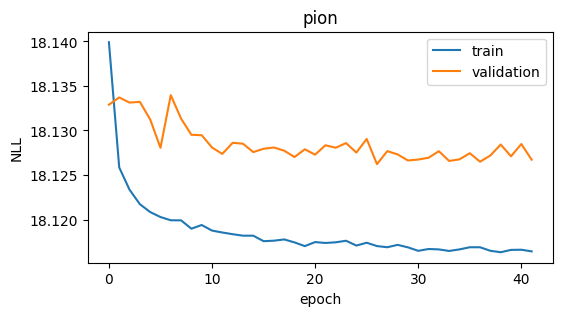

In [5]:
particle = PARTICLES[0]
data = DATA[particle]
NETS = {particle: make_model()}
hist = fit(NETS[particle], data, f"{OUT_DIR}/{particle}/cnn.pt", epochs=60, lr=3e-3, smooth=1e-4)
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.title(particle); plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 4b. Capacity check with a single run

- **Train–val gap:** if the network overfits, the train NLL drops well below the validation NLL.
- **Comparison with the validated-sufficient MLP** (05, `load_mlp`): per-event paired validation NLL difference $\Delta = \mathrm{NLL_{CNN}} - \mathrm{NLL_{MLP}}$.
  If $\Delta < 1\,\mathrm{SE}$ (or negative), the CNN capacity is sufficient. Otherwise we double the channels and retrain (`results/pion/cnn_x2.pt`).

In [6]:
def capacity_check(net):
    tr, va = float(test_nll(net, data["train"]).mean()), test_nll(net, data["val"])
    row = {"params": sum(p.numel() for p in net.parameters()), "train NLL": tr, "val NLL": float(va.mean()), "train−val": tr - float(va.mean())}
    if MLP is not None:
        d = va - test_nll(MLP, data["val"])
        row.update({"MLP val NLL": float(test_nll(MLP, data["val"]).mean()), "Δ vs MLP": float(d.mean()), "SE": float(d.std(ddof=1) / np.sqrt(len(d)))})
        row["sufficient"] = row["Δ vs MLP"] < row["SE"]
    return row


MLP = load_mlp(particle)
print("reference MLP:", "loaded" if MLP is not None else "missing (run 05 first) – only the train–val gap is checked")
CAP = {"CNN " + str(CHANS): capacity_check(NETS[particle])}
if MLP is not None and not CAP["CNN " + str(CHANS)]["sufficient"]:
    print("capacity not demonstrated -> the single fallback step: all channels x2")
    big = tuple(2 * c for c in CHANS)
    net2 = make_model(big)
    fit(net2, data, f"{OUT_DIR}/{particle}/cnn_x2.pt", epochs=60, lr=3e-3, smooth=1e-4)
    CAP["CNN " + str(big)] = capacity_check(net2)
    if CAP["CNN " + str(big)]["val NLL"] < CAP["CNN " + str(CHANS)]["val NLL"]:
        NETS[particle] = net2
CAP_TABLE = pd.DataFrame(CAP).T
display(CAP_TABLE)
CAP_TABLE.to_csv(f"{OUT_DIR}/{particle}/cnn_capacity.csv")

reference MLP: loaded


,params,train NLL,val NLL,train−val,MLP val NLL,Δ vs MLP,SE,sufficient
"CNN (48, 48, 32, 32, 16)",121939,18.107756,18.118469,-0.010714,18.119101,-0.000633,0.000284,True


## 5. Distillation

Four formula families ($\{$`gamma`, `plateau`$\} \times \{$`core_tail`, `gauss_exp`$\}$) with first- and second-degree $\ln p$ dependence are fitted
to the CNN maps. We keep the simplest one within 0.005 nat KL of the best.

**Here the formula is fitted to the network maps, not to the data** (KL divergence, 30 $\ln p$ values between the 2–98% quantiles of the training data, without convolution).
The map is used only up to depth $z_{cut}$ (still in front of the back face for 90% of training events). The formula quality is therefore also affected by the network's errors and
artefacts; the test NLL shows the result measured against the data. The result is saved to `results/pion/cnn_formula.pt`.

In [7]:
CANDIDATES = [("gamma", "core_tail"), ("gamma", "gauss_exp"), ("plateau", "core_tail"), ("plateau", "gauss_exp")]
FORMULAS = {}
for particle in PARTICLES:
    print(f"===== {particle} =====")
    path = f"{OUT_DIR}/{particle}/cnn_formula.pt"
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        f = Formula(ck["long"], ck["lat"], ck["degree"]).to(DEVICE)
        f.load_state_dict(ck["state"])
        print("loaded", path)
        display(ck["table"])
    else:
        f, table, z_cut = distill(NETS[particle], DATA[particle]["train"], CANDIDATES, steps=600)
        display(table.sort_values("KL"))
        torch.save({"long": f.long, "lat": f.lat, "degree": f.degree, "state": f.state_dict(), "table": table}, path)
    FORMULAS[particle] = f

===== pion =====
loaded results/pion/cnn_formula.pt


,longitudinal,lateral,degree,params,KL
0,gamma,core_tail,1,15,0.099968
1,gamma,core_tail,2,21,0.090199
2,gamma,gauss_exp,1,15,0.118851
3,gamma,gauss_exp,2,21,0.109222
4,plateau,core_tail,1,19,0.095405
5,plateau,core_tail,2,27,0.086761
6,plateau,gauss_exp,1,19,0.114562
7,plateau,gauss_exp,2,27,0.105962


## 6. Results

**What to look for:**
- **Test NLL:** whether the NLLs of the network and the formula are close. If so, the formula captures almost everything the network learned.
  Reference: the test NLL of the GFlash formula (01) and of the MLP (05); the network must not be worse, otherwise it is not flexible enough or trained poorly.
- **Profiles:** both the network (green) and the formula (purple) should follow the data (black).
- **True shape and 3D:** whether the network shape is smooth. The network may learn small sub-cell artefacts (e.g. a thin spike on the axis),
  because the data do not constrain it there; the formula smooths these out.
- **Formula:** which family won, and how its parameters depend on momentum.

## pion

test NLL  mlp (05): 18.1221
test NLL  mlp_formula (05): 18.1634
test NLL  GFlash (01): 18.1563
test NLL  cnn: 18.1218   formula: 18.1617   difference (paired): +0.0399 ± 0.0013


/tmp/ipykernel_326416/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### The distilled formula (gamma × core_tail, degree 2)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-17.27 -2.801\,L +1.515\,L^2$ | – |
| `log_tmax` | $+3.975 +0.4578\,L -0.04568\,L^2$ | – |
| `log_am1` | $-0.8857 -0.1495\,L +0.06647\,L^2$ | – |
| `log_rc` | $+3.114 +0.1154\,L -0.05172\,L^2$ | +1.254 |
| `log_ratio` | $+1.116 -0.2617\,L +0.06797\,L^2$ | +0.1511 |
| `logit_pc` | $+0.8552 -0.8139\,L +0.2459\,L^2$ | -0.3576 |

Number of parameters: **21**

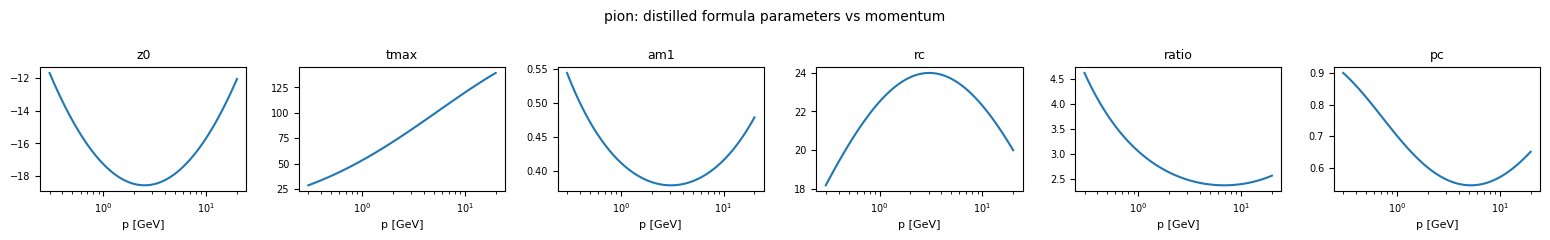

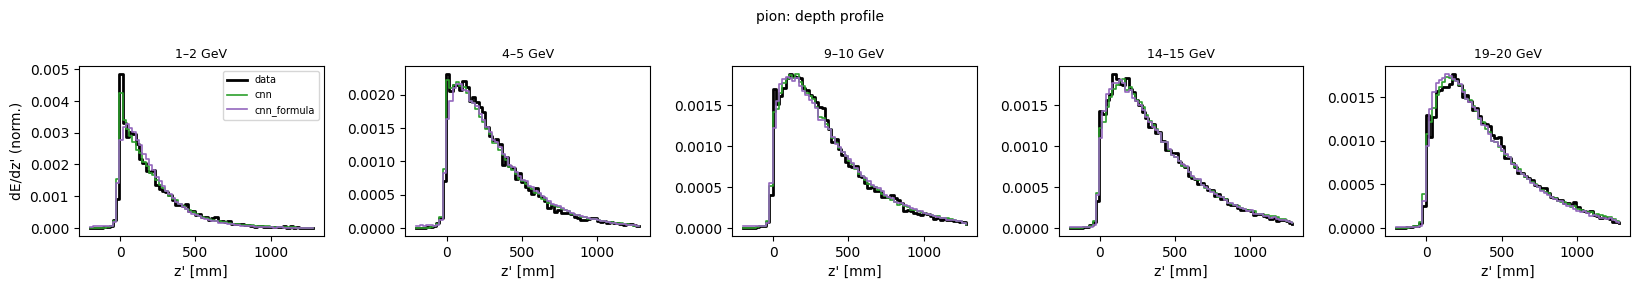

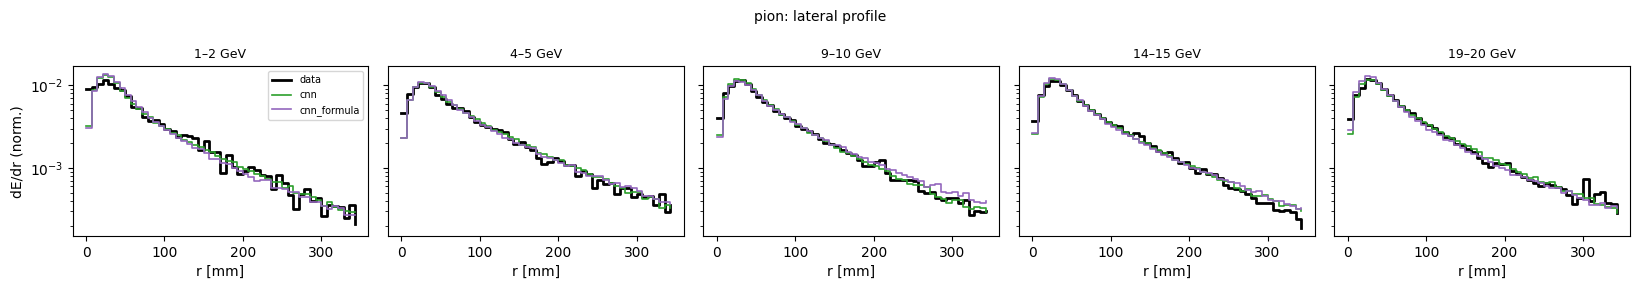

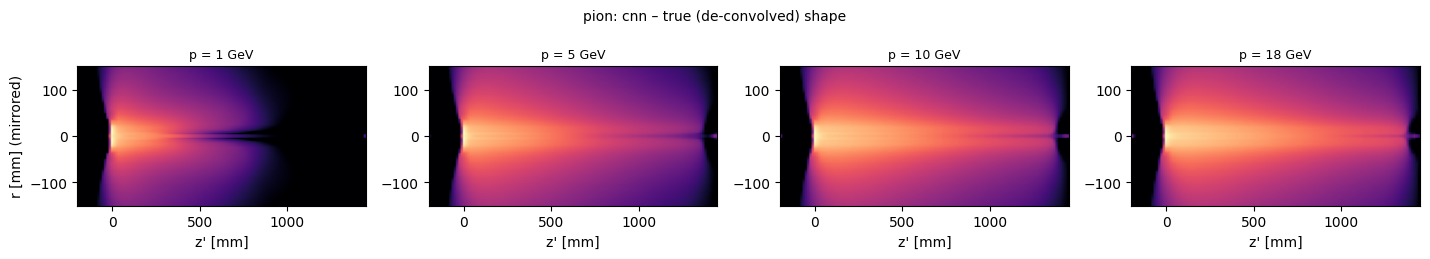

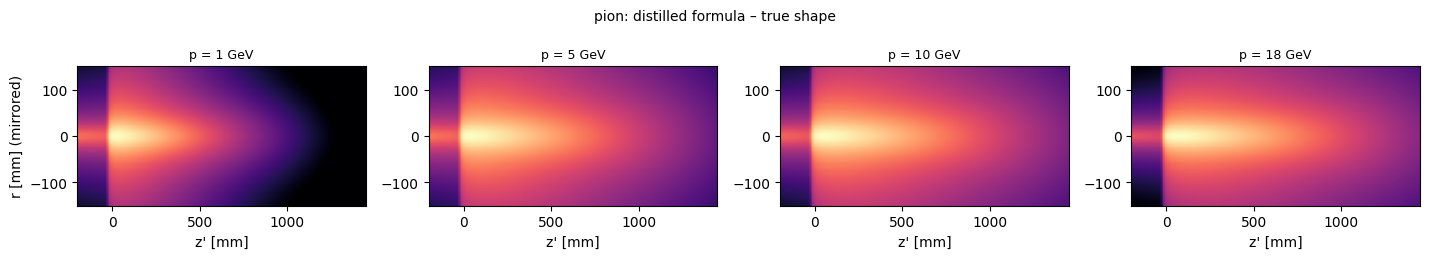

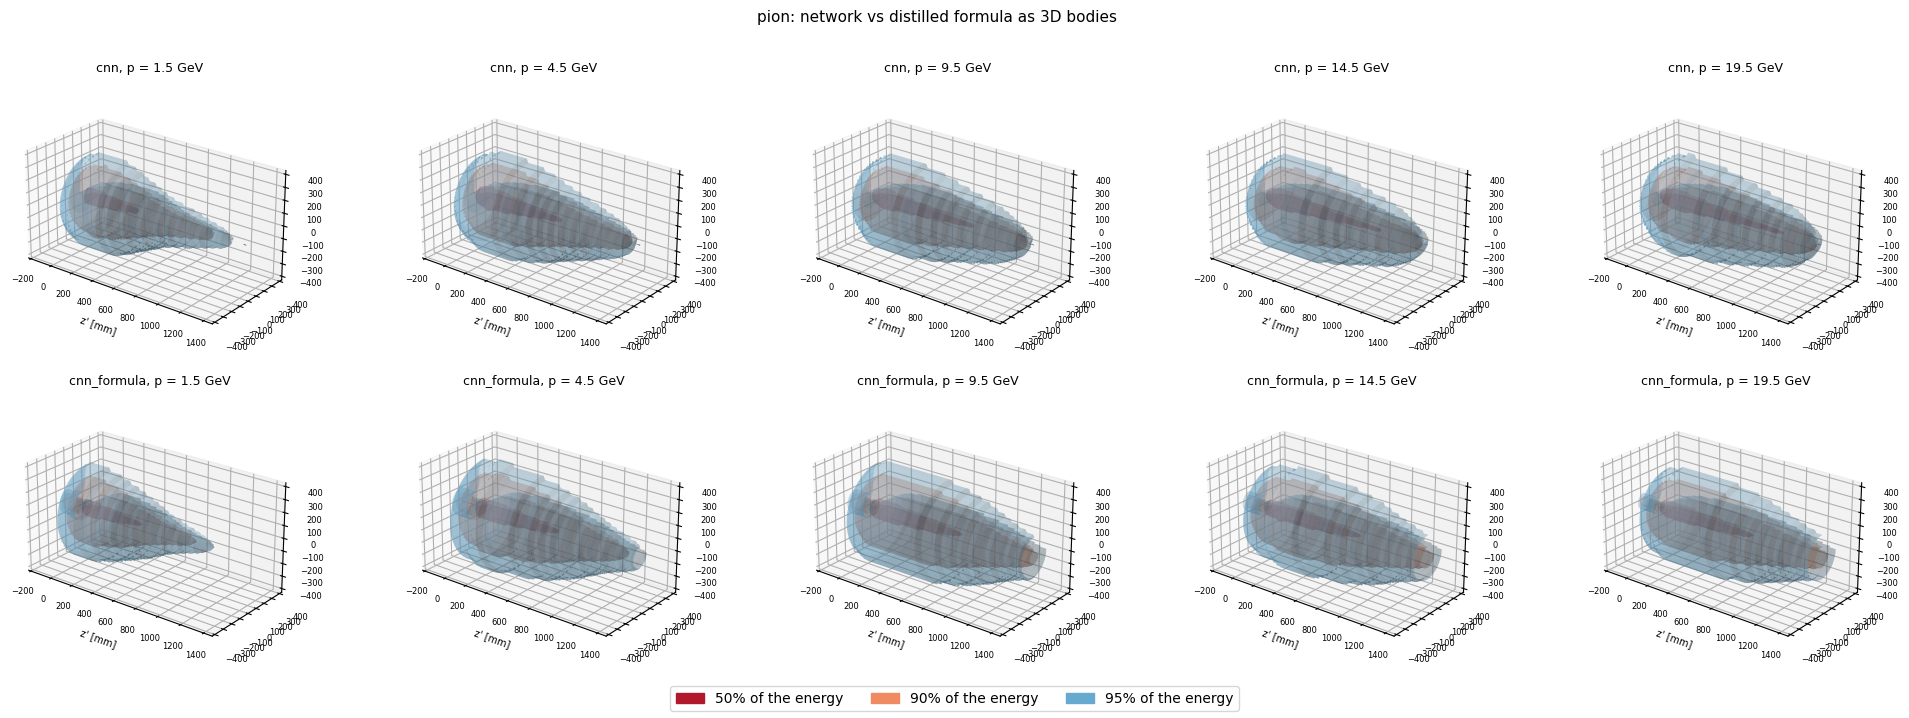

exported pion/cnn: test NLL = 18.1218
exported pion/cnn_formula: test NLL = 18.1617


In [8]:
for particle in PARTICLES:
    display(Markdown(f"## {particle}"))
    data, net, f = DATA[particle], NETS[particle], FORMULAS[particle]
    nll_net, nll_f = test_nll(net, data["test"]), test_nll(f, data["test"])
    gf_path = f"{OUT_DIR}/{particle}/export_gflash.pt"
    for nm in ("mlp", "mlp_formula"):
        pth = f"{OUT_DIR}/{particle}/export_{nm}.pt"
        if os.path.exists(pth):
            print(f"test NLL  {nm} (05): {torch.load(pth, weights_only=False)['test_nll'].mean():.4f}")
    if os.path.exists(gf_path):
        print(f"test NLL  GFlash (01): {torch.load(gf_path, weights_only=False)['test_nll'].mean():.4f}")
    d = nll_f - nll_net
    print(f"test NLL  cnn: {nll_net.mean():.4f}   formula: {nll_f.mean():.4f}   "
          f"difference (paired): {d.mean():+.4f} ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    display(Markdown(f.describe(f"The distilled formula ({f.long} × {f.lat}, degree {f.degree})")))
    formula_curves(f, f"{particle}: distilled formula parameters vs momentum")
    hits = data["test"].hits()
    samples = {"cnn": sample_folded(net, data["test"]), "cnn_formula": sample_folded(f, data["test"])}
    profile_plot(hits, samples, "z", f"{particle}: depth profile")
    profile_plot(hits, samples, "r", f"{particle}: lateral profile")
    shape_map(net, title=f"{particle}: cnn – true (de-convolved) shape")
    shape_map(f, title=f"{particle}: distilled formula – true shape")
    bodies_3d({"cnn": net, "cnn_formula": f}, title=f"{particle}: network vs distilled formula as 3D bodies")
    export(particle, "cnn", net, data)
    export(particle, "cnn_formula", f, data, f.describe(f"CNN → formula ({particle})"))

## 7. Unified comparison: seven shapes with the same metric

Same metric and same plots as in the comparisons of notebooks 03 and 05, with the two new CNN shapes:

| | formula | what it describes | parameters |
|---|---|---|---|
| **GFlash $r_{95}$** (01) | Gamma × (core + tail) | 95% energy region of the **average** shower | ~15–60 (global) |
| **Envelope** (02) | $r = A\,u^{a}e^{-bu}$ | hull sized for 98% of showers | 4 / bin |
| **Drop** (03) | $r = A\,g\!\left(\frac{z'-z_0}{L}\right)$ | same kind of hull, finite, fixed shape | 3 / bin |
| **MLP $r_{95}$** (05) | neural field | 95% energy region of the **average** shower, without a fixed form | network weights (global) |
| **MLP-formula $r_{95}$** (05) | distilled formula | the same, with a formula extracted from the network | formula parameters (global) |
| **CNN $r_{95}$** (06) | convolutional decoder | 95% region of the average shower | network weights (global) |
| **CNN-formula $r_{95}$** (06) | distilled formula | the same, with a formula extracted from the CNN | formula parameters (global) |

**Important for interpreting the metric:** the $r_{95}$ shapes (GFlash, network, formula) are 95% regions of the **average**, de-convolved shower; they were not built for the "95% in 98% of showers" criterion, whereas the envelopes were. Lower coverage and volume of the $r_{95}$ shapes is therefore expected and not a model failure. The volume of the envelope and the drop is the **analytic** volume of the whole body (the same quantity the fit minimises); for $r_{95}$ it is the volume summed on the grid (up to $Z_{MAX}$).

**Common metric in every 1 GeV bin:**
- **Volume** $V$ in litres (for the density models $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid).
- **Test coverage:** fraction of test showers with at least 95% of their energy inside the shape (points spread within each cell).
  The envelopes are optimised for 0.98; the $r_{95}$ shapes describe the **average** shower, so their coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

GFlash is loaded from `export_gflash.pt`, the envelope from `envelope.pt`, the drop from `drop.pt`, the MLP and MLP-formula from `export_mlp.pt` / `export_mlp_formula.pt` (05); any missing one is skipped.

In [9]:
F_E, F_EV = 0.95, 0.98
G_MAX = 0.5 * 0.75 ** 1.5
zc, z_edges = ZC.cpu().numpy(), Z_EDGES.cpu().numpy()


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K (the same as in 02 and 03).
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z').
    inside = torch.as_tensor(P["r"].cpu().numpy() <= radius_fn(P["z"].cpu().numpy()), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def drop_radius(z, e):
    t = (np.asarray(z, dtype=float) - e["z0"]) / e["L"]
    return np.where((t > 0) & (t < 1), e["A"] * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


@torch.no_grad()
def r95_of(model, p):
    return iso_radius(model(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy(), F_E)


def grid_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


load = lambda name: torch.load(f"{OUT_DIR}/{particle}/{name}", weights_only=False) if os.path.exists(f"{OUT_DIR}/{particle}/{name}") else None
GF = TableModel(load("export_gflash.pt")) if load("export_gflash.pt") is not None else None
ENV, DROP = load("envelope.pt") or {}, load("drop.pt") or {}
TM = lambda name: TableModel(load(f"export_{name}.pt")) if load(f"export_{name}.pt") is not None else None
MODELS = {"GFlash r95": GF, "MLP r95": TM("mlp"), "MLP-formula r95": TM("mlp_formula"), "CNN r95": NETS[particle], "CNN-formula r95": FORMULAS[particle]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
print("GFlash export:", GF is not None, "| envelope bins:", len(ENV), "| drop bins:", len(DROP))

rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = float(data["test"].ev["p"][te].mean())
    shapes, grid = {}, {}
    for name, m in MODELS.items():
        grid[name] = r95_of(m, pm)
        shapes[name] = grid_fn(grid[name])
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if b in DROP:
        shapes["drop"] = lambda z, e=DROP[b]: drop_radius(z, e)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name in grid:                                        # exact grid volume for the step profiles
            s["V_L"] = float(np.sum(np.pi * grid[name] ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
ORDER = ["GFlash r95", "envelope", "drop", "MLP r95", "MLP-formula r95", "CNN r95", "CNN-formula r95"]
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)])
summary["param"] = summary.index.map({"GFlash r95": f"{GF.n_params if GF is not None and hasattr(GF, 'n_params') else '~15–60'} (global)",
                                       "envelope": "4 / bin", "drop": "3 / bin",
                                       "MLP r95": f"{MODELS['MLP r95'].n_params if 'MLP r95' in MODELS else '–'} (global)",
                                       "CNN r95": f"{sum(p.numel() for p in NETS[particle].parameters())} (global)",
                                       "CNN-formula r95": f"{FORMULAS[particle].n_params()} (global)",
                                       "MLP-formula r95": f"{MODELS['MLP-formula r95'].n_params if 'MLP-formula r95' in MODELS else '–'} (global)"})
display(summary.round(3))

GFlash export: True | envelope bins: 20 | drop bins: 20


V_L                                                      \
formula  CNN r95 CNN-formula r95 GFlash r95  MLP r95 MLP-formula r95   
bin                                                                    
0         69.358          77.090     62.781   70.606          82.409   
1        300.541         251.604    264.508  328.889         261.605   
2        401.578         387.130    364.550  409.279         399.198   
3        434.199         465.035    402.603  422.384         475.256   
4        429.139         511.915    420.787  424.243         520.016   
5        408.735         537.822    430.890  424.755         544.328   
6        390.954         552.694    439.010  423.991         557.877   
7        387.218         559.046    446.336  424.338         562.113   
8        392.876         560.333    453.914  423.887         561.934   
9        401.948         558.636    461.567  424.122         557.806   
10       410.099         554.059    470.708  424.486         551.256   
11       417.271         547.404    479.528  425.627         543.618   
12       422.270         540.495    489.427  425.879         533.771   
13       426.393         532.462    499.877  426.940         524.622   
14       430.355         523.569    510.611  427.597         513.571   
15       433.576         513.962    522.788  428.543         502.110   
16       436.175         504.641    534.583  429.609         491.681   
17       438.671         493.743    547.490  429.973         479.939   
18       441.125         483.993    560.329  431.112         468.053   
19       443.027         473.730    573.534  432.038         456.564   

                            cov_test                                     \
formula      drop  envelope  CNN r95 CNN-formula r95 GFlash r95 MLP r95   
bin                                                                       
0         845.724  1103.170    0.730           0.739      0.699   0.728   
1        1480.837  1571.231    0.782           0.724      0.734   0.800   
2        1631.392  1847.252    0.780           0.745      0.728   0.785   
3        1716.116  2026.870    0.737           0.748      0.692   0.722   
4        1786.462  2039.259    0.767           0.793      0.737   0.753   
5        1645.218  2025.450    0.757           0.832      0.768   0.773   
6        1511.348  1893.786    0.737           0.835      0.767   0.769   
7        1636.977  1819.815    0.740           0.849      0.773   0.772   
8        1562.614  1908.750    0.743           0.825      0.760   0.763   
9        1543.277  1700.842    0.768           0.852      0.793   0.785   
10       1483.483  1642.425    0.780           0.848      0.803   0.788   
11       1650.938  1987.542    0.785           0.861      0.821   0.799   
12       1523.458  1787.144    0.775           0.841      0.799   0.776   
13       1590.118  1886.369    0.760           0.805      0.790   0.758   
14       1433.529  1596.955    0.789           0.844      0.825   0.788   
15       1512.652  1613.459    0.783           0.824      0.829   0.769   
16       1481.671  1627.373    0.783           0.808      0.824   0.780   
17       1461.109  1709.741    0.770           0.804      0.821   0.761   
18       1589.613  1758.545    0.785           0.807      0.837   0.779   
19       1456.731  1562.293    0.795           0.812      0.864   0.791   

                                         
formula MLP-formula r95   drop envelope  
bin                                      
0                 0.742  0.972    0.978  
1                 0.730  0.972    0.975  
2                 0.754  0.979    0.980  
3                 0.757  0.969    0.973  
4                 0.797  0.979    0.979  
5                 0.832  0.984    0.984  
6                 0.835  0.972    0.973  
7                 0.856  0.977    0.977  
8                 0.832  0.973    0.976  
9                 0.849  0.975    0.976  
10                0.845  0.981    0.983  
11                0.856  0.985    0.983  


,V_L,cov_test,z_env,r_max,param
formula,,,,,
GFlash r95,446.791,0.783,138.575,395.520,27 (global)
envelope,1755.414,0.978,310.375,731.426,4 / bin
drop,1527.163,0.978,402.200,701.706,3 / bin
MLP r95,402.915,0.772,202.450,383.761,3841 (global)
MLP-formula r95,479.386,0.808,217.250,398.420,21 (global)
CNN r95,395.775,0.767,163.800,375.277,121939 (global)
CNN-formula r95,481.468,0.810,174.700,395.424,21 (global)


**What to look for in the table and plots:**
- **MLP $r_{95}$ vs. GFlash $r_{95}$:** both are the 95% region of the average shower. If they are close, the GFlash functional form is
  good enough; where they differ (e.g. shower start, lateral tail), the network learned something the formula cannot describe.
- **CNN vs. MLP:** two different networks on the same data; if their $r_{95}$ are close, the shape is not an artefact of the architecture.
- **CNN-formula vs. CNN, MLP-formula vs. MLP:** if the $r_{95}$ and coverage of the distilled formula are close to those of the network, distillation lost no essential information.
- **Density vs. envelope:** the coverage of the three $r_{95}$ shapes is expected to stay well below 0.98, that of the two envelopes ~0.98. This reflects the two approaches, not an error.

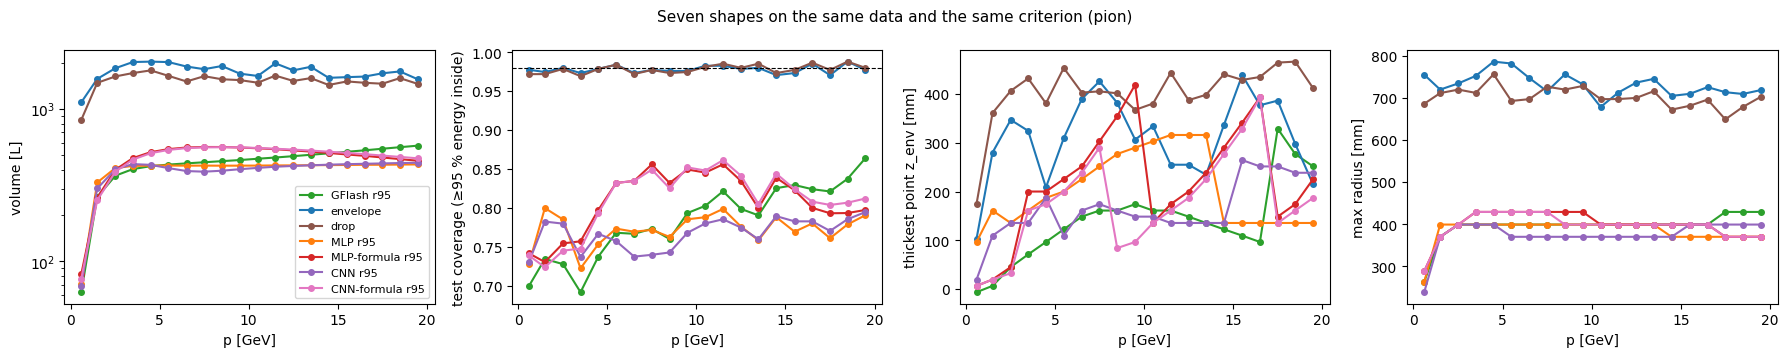

In [10]:
colors = {"GFlash r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown", "MLP r95": "tab:orange", "MLP-formula r95": "tab:red", "CNN r95": "tab:purple", "CNN-formula r95": "tab:pink"}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for name in [o for o in ORDER if o in set(CMP.formula)]:
    g = CMP[CMP.formula == name]
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend(fontsize=8)
fig.suptitle("Seven shapes on the same data and the same criterion (pion)", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the comparison plots of 03 and 05

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** GFlash $r_{95}$. **Blue:** envelope. **White:** drop. **Orange:** MLP $r_{95}$. **Red dashed:** MLP-formula $r_{95}$. **Violet:** CNN $r_{95}$. **Pink dashed:** CNN-formula $r_{95}$.

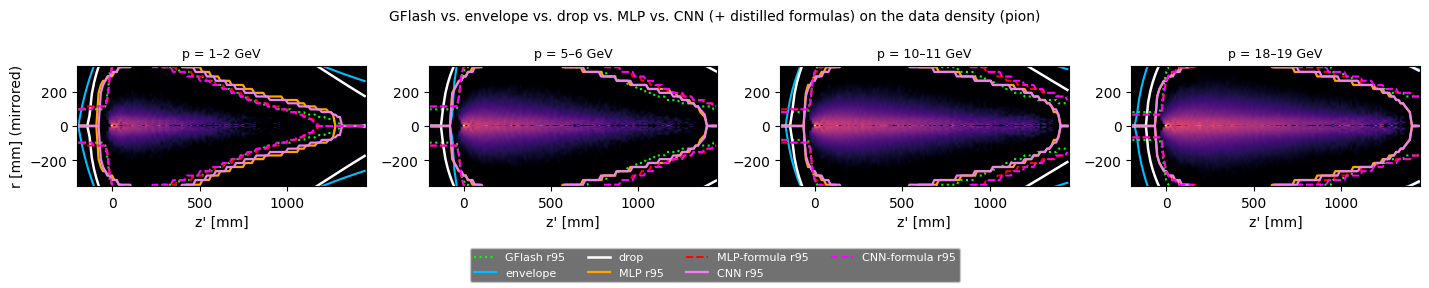

In [11]:
STYLE = {"GFlash r95": dict(c="lime", ls=":", lw=1.5), "envelope": dict(c="deepskyblue", lw=1.5), "drop": dict(c="white", lw=1.8),
         "MLP r95": dict(c="orange", lw=1.6), "MLP-formula r95": dict(c="red", ls="--", lw=1.4),
         "CNN r95": dict(c="violet", lw=1.6), "CNN-formula r95": dict(c="magenta", ls="--", lw=1.4)}


def compare_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
        if b in ENV:
            curves["envelope"] = envelope_r(zc, ENV[b])
        if b in DROP:
            curves["drop"] = drop_radius(zc, DROP[b])
        for name in ORDER:
            if name in curves:
                ax.plot(zc, curves[name], **STYLE[name]); ax.plot(zc, -curves[name], **STYLE[name])
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], label=n, **STYLE[n]) for n in ORDER if n in set(CMP.formula)]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    plt.show()


compare_map(data["train"], title="GFlash vs. envelope vs. drop vs. MLP vs. CNN (+ distilled formulas) on the data density (pion)")

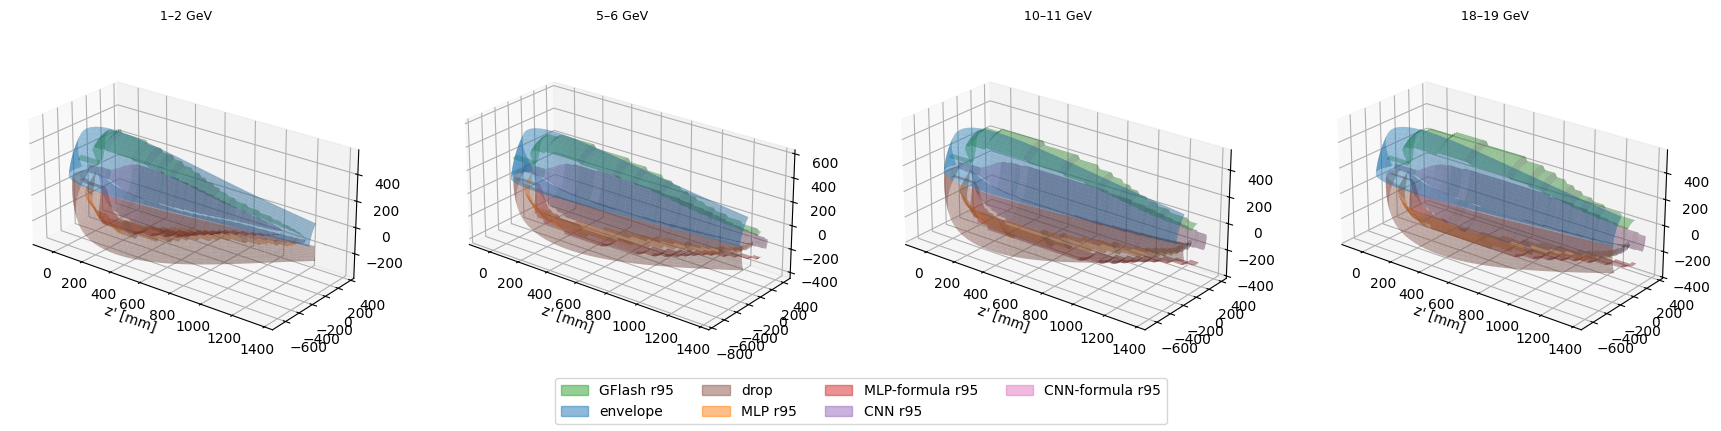

saved: comparison_7shapes.csv


In [12]:
# the five bodies side by side in 3D: each body in its own sector, so all of them stay visible
show = [1, 5, 10, 18]
fig = plt.figure(figsize=(4.4 * len(show), 4.2))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
    if b in ENV:
        bodies["envelope"] = envelope_r(zc, ENV[b])
    if b in DROP:
        bodies["drop"] = drop_radius(zc, DROP[b])
    names = [n for n in ORDER if n in bodies]
    for k, name in enumerate(names):
        f0 = 0.5 * np.pi + 1.5 * np.pi * k / len(names); f1 = 0.5 * np.pi + 1.5 * np.pi * (k + 1) / len(names)
        ax_.plot_surface(*revolve(zc, bodies[name], f0, f1, 12), color=colors[name], alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[n], alpha=0.5, label=n) for n in ORDER if n in set(CMP.formula)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/{particle}/comparison_7shapes.csv", index=False)
print("saved: comparison_7shapes.csv")